# Отчёт по лабораторной работе №6 по теме «Линейная регрессия»

**Выполнил:** студент группы 12002408

Блинов Кирилл Игоревич

**Проверил:** ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич


<p align="justify"><strong>Цель работы:</strong> изучить подготовку данных, обучение линейной регрессии и оценку качества модели в Scikit-learn.</p>


<h2 align="center">Задание</h2>

Выполнить 10 заданий по исследованию набора Diabetes и построению модели линейной регрессии.


## Ход работы


Набор данных Diabetes (Диабет) содержит 442 образца с 10-ю признаками: возраст, пол, индекс массы тела, средний показатель давления крови и шесть измерений сыворотки крови. Целевое значение - количественный показатель прогрессирования заболевания через год после анализов.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
diabetes = datasets.load_diabetes()


### Задание №1

Выведите описание набора данных и наименование признаков.


In [2]:
print(diabetes.DESCR)
print('Названия признаков:', diabetes.feature_names)
print('Размер набора:', diabetes.data.shape)


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

### Задание №2

Из загруженного набора данных создайте DataFrame, содержащий как признаки, так и целевое значение. Выведите первые 5 строк набора.


In [3]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target
df.head(5)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Задание №3

Выведите информацию о типах данных в наборе. Имеются ли в наборе категориальные признаки? Имеются ли в наборе данные имеющие значение null?


In [4]:
df.info()
print('\nКоличество пропусков по столбцам:')
print(df.isnull().sum())
print('\nВсего пропусков:', df.isnull().sum().sum())
print('\nУникальные значения sex:', np.unique(df['sex']))


<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Количество пропусков по столбцам:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Всего пропусков: 0

Уникальные значения sex: [-0.04464164  0.05068012]


Все столбцы имеют числовой тип `float64`, пропусков нет. При этом `sex`
по смыслу является бинарным категориальным признаком: в загруженном
наборе он уже закодирован числами и масштабирован, как и остальные
признаки. Дополнительное кодирование для данной модели не требуется.


### Задание №4

Постройте матрицу корреляции.


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000,0.174,0.185,0.335,0.260,0.219,-0.075,0.204,0.271,0.302,0.188
sex,0.174,1.000,0.088,0.241,0.035,0.143,-0.379,0.332,0.150,0.208,0.043
bmi,0.185,0.088,1.000,0.395,0.250,0.261,-0.367,0.414,0.446,0.389,0.586
bp,0.335,0.241,0.395,1.000,0.242,0.186,-0.179,0.258,0.393,0.390,0.441
s1,0.260,0.035,0.250,0.242,1.000,0.897,0.052,0.542,0.516,0.326,0.212
s2,0.219,0.143,0.261,0.186,0.897,1.000,-0.196,0.660,0.318,0.291,0.174
s3,-0.075,-0.379,-0.367,-0.179,0.052,-0.196,1.000,-0.738,-0.399,-0.274,-0.395
s4,0.204,0.332,0.414,0.258,0.542,0.660,-0.738,1.000,0.618,0.417,0.430
s5,0.271,0.150,0.446,0.393,0.516,0.318,-0.399,0.618,1.000,0.465,0.566
s6,0.302,0.208,0.389,0.390,0.326,0.291,-0.274,0.417,0.465,1.000,0.382


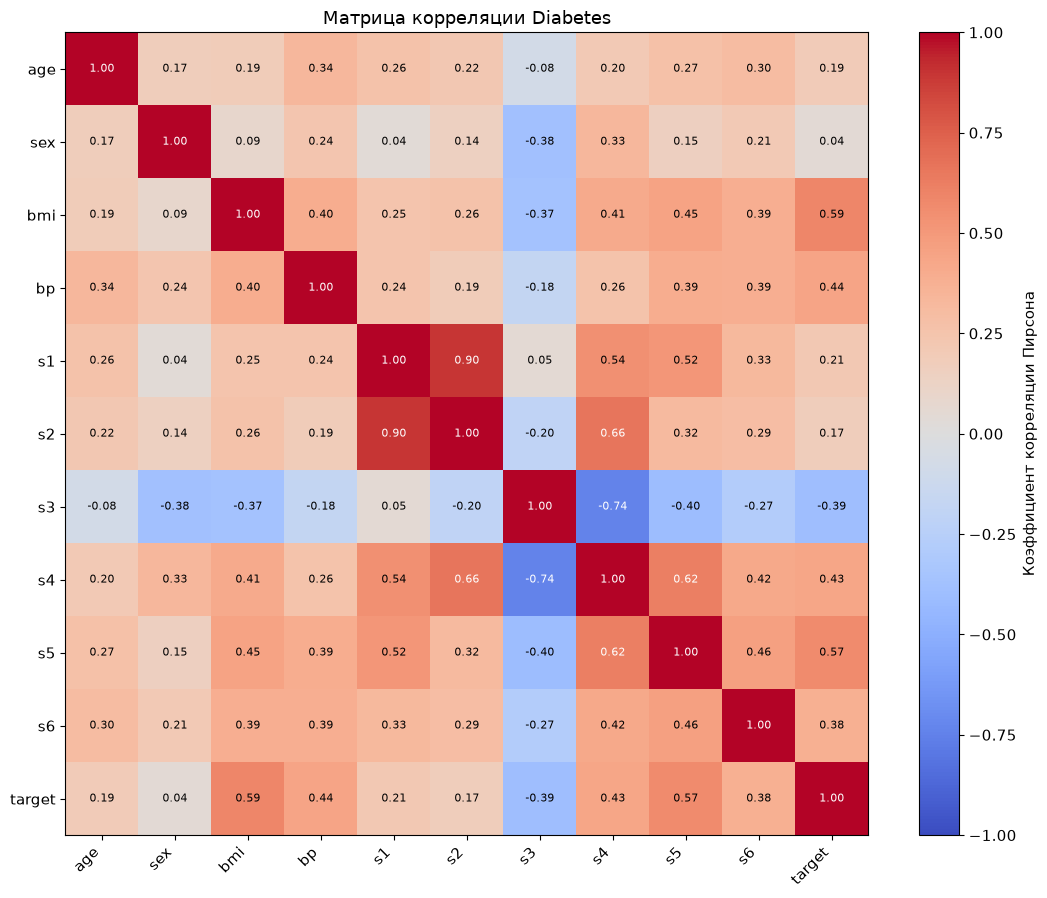

In [5]:
correlation = df.corr()
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
positions = np.arange(len(correlation.columns))
ax.set_xticks(positions, correlation.columns, rotation=45, ha='right')
ax.set_yticks(positions, correlation.index)
for row in range(len(correlation)):
    for col in range(len(correlation)):
        value = correlation.iloc[row, col]
        ax.text(col, row, f'{value:.2f}', ha='center', va='center',
                fontsize=8, color='white' if abs(value) > 0.6 else 'black')
fig.colorbar(image, ax=ax, label='Коэффициент корреляции Пирсона')
ax.set_title('Матрица корреляции Diabetes')
fig.tight_layout()
plt.show()


### Задание №5

Постройте диаграмму рассеяния целевого значение и признака, коэффициент корреляции которого с  целевым значением, самый высокий.


Корреляция признаков с целевым значением:
bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
s3    -0.3948
Name: target, dtype: float64

Наибольшая корреляция: bmi 0.5865


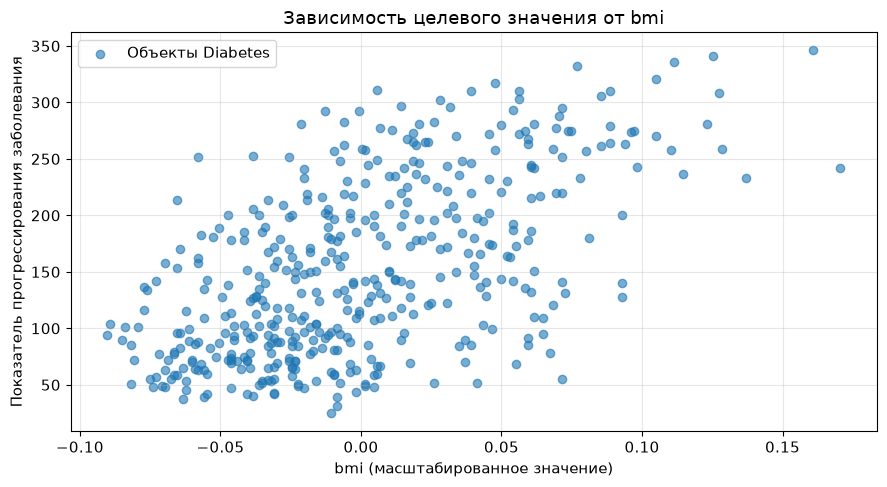

In [6]:
target_correlation = correlation['target'].drop('target').sort_values(ascending=False)
print('Корреляция признаков с целевым значением:')
print(target_correlation.round(4))
best_feature = target_correlation.index[0]
print('\nНаибольшая корреляция:', best_feature,
      round(target_correlation.iloc[0], 4))

fig, ax = plt.subplots()
ax.scatter(df[best_feature], df['target'], alpha=0.6,
           label='Объекты Diabetes')
ax.set(xlabel=f'{best_feature} (масштабированное значение)',
       ylabel='Показатель прогрессирования заболевания',
       title=f'Зависимость целевого значения от {best_feature}')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


### Задание №6

Сформируйте набор признаков (X) из 5 признаков с самым высоким коэффициентом корреляции с целевым значением. Сформируйте набор для целевого значения (y).


In [7]:
# По условию берём пять наибольших коэффициентов, без модуля.
selected_features = target_correlation.head(5).index.tolist()
X = df[selected_features]
y = df['target']
print('Выбранные признаки:', selected_features)
print('\nИх корреляция с target:')
print(target_correlation.head(5).round(4))
print('\nРазмер X:', X.shape)
print('Размер y:', y.shape)


Выбранные признаки: ['bmi', 's5', 'bp', 's4', 's6']

Их корреляция с target:
bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s6     0.3825
Name: target, dtype: float64

Размер X: (442, 5)
Размер y: (442,)


По условию задания признаки выбраны по корреляции на всём наборе.
Для независимой оценки новой модели отбор признаков следует проводить
только на обучающей части, чтобы тестовые целевые значения не влияли
на выбор признаков.


### Задание №7

Разделите набор данных на два, одни для обучения модели другой для проверки. Тестовый набор должен содержать 25 процентов данных.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print('Обучающая выборка:', X_train.shape, y_train.shape)
print('Тестовая выборка:', X_test.shape, y_test.shape)
print('Доля тестовой выборки:', round(len(X_test) / len(X), 3))


Обучающая выборка: (331, 5) (331,)
Тестовая выборка: (111, 5) (111,)
Доля тестовой выборки: 0.251


### Задание №8

Выполните обучение модели.


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
print('Свободный член:', round(model.intercept_, 4))
print('\nКоэффициенты модели:')
print(pd.Series(model.coef_, index=selected_features).round(4))

y_pred = model.predict(X_test)
comparison = pd.DataFrame({'Фактическое значение': y_test,
                           'Предсказание': y_pred})
display(comparison.head(5).round(2))


Свободный член: 151.6484

Коэффициенты модели:
bmi    617.3449
s5     406.1149
bp     311.9578
s4     103.5398
s6      18.9067
dtype: float64


,Фактическое значение,Предсказание
287,219.0,159.45
211,70.0,167.61
72,202.0,178.94
321,230.0,264.32
73,111.0,139.76


### Задание №9

Рассчитайте Root mean squared error (RMSE)


In [10]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'RMSE на тестовой выборке: {rmse:.4f}')


RMSE на тестовой выборке: 52.6639


RMSE измеряется в единицах целевого показателя: чем меньше ошибка, тем точнее предсказания.


### Задание №10

Рассчитайте R² (коэффициент детерминации)


In [11]:
r2 = r2_score(y_test, y_pred)
print(f'R² на тестовой выборке: {r2:.4f}')
print(f'Доля объяснённой вариации: {r2:.2%}')


R² на тестовой выборке: 0.4984
Доля объяснённой вариации: 49.84%


R² рассчитывается непосредственно функцией `r2_score`, без извлечения квадратного корня. Значение показывает долю вариации целевого показателя, объясняемую моделью относительно постоянного прогноза среднего тестовой выборки.


## Вывод

Изучил подготовку данных, обучение линейной регрессии и оценку качества модели в Scikit-learn.


## Ответы на вопросы для защиты


### 1. Какие типы машинного обучения вы знаете?

Основные типы – обучение с учителем, без учителя, с частичным привлечением учителя и обучение с подкреплением. При обучении с учителем решают задачи регрессии и классификации; без учителя – например, кластеризацию и снижение размерности.


### 2. Чем отличается обучение с учителем и без учителя?

При обучении с учителем есть признаки X и правильные ответы y: модель учится предсказывать ответы для новых объектов. В этой работе ответом служит показатель прогрессирования заболевания. При обучении без учителя правильных ответов нет, модель ищет структуру в признаках.


### 3. Чем пакетное обучение отличается от динамического?

При пакетном обучении модель обучается на подготовленном наборе данных; для учёта новых данных её обычно переобучают. При динамическом, или онлайн-обучении, параметры обновляются последовательно по новым объектам либо небольшим порциям данных. Не все модели поддерживают такое обновление; у некоторых моделей Scikit-learn для него предусмотрен `partial_fit`.


### 4. Чем обучение на основе образцов отличается от обучения на основе модели?

Методы на основе образцов сохраняют обучающие примеры и предсказывают ответ по сходству с ними, как k ближайших соседей. Методы на основе модели подбирают параметры зависимости и используют полученную функцию для предсказания. Линейная регрессия относится ко второму подходу.


### 5. Что такое линейная регрессия?

Линейная регрессия предсказывает числовой ответ как сумму свободного члена и признаков с весами: `y_pred = b + w1*x1 + ... + wn*xn`. Обычный метод наименьших квадратов подбирает параметры, минимизируя сумму квадратов ошибок на обучающей выборке. В работе использована `LinearRegression`.


### 6. Что такое градиентный спуск?

Это итерационный способ минимизации функции ошибки. На каждом шаге параметры меняют в направлении, противоположном градиенту: `w = w - learning_rate * gradient`. Скорость обучения задаёт размер шага. Использованная здесь `LinearRegression` решает задачу наименьших квадратов без обязательного применения градиентного спуска.


### 7. Как правильно обрабатывать категориальные признаки?

Категории преобразуют в числовое представление. Для категорий без порядка обычно используют one-hot-кодирование, для упорядоченных категорий – кодирование с сохранением порядка. Произвольные номера категорий могут создать ложный числовой порядок. Преобразование обучают на тренировочных данных и затем применяют к тестовым, например через `OneHotEncoder(handle_unknown="ignore")`. В Diabetes признак `sex` уже численно закодирован и масштабирован.


### 8. Что такое матрица корреляции?

Это таблица попарных коэффициентов корреляции признаков. Коэффициент Пирсона лежит от -1 до 1: положительное значение соответствует совместному росту, отрицательное – изменению в противоположных направлениях. Значение около нуля означает слабую линейную связь, но не исключает нелинейной зависимости. Корреляция сама по себе не доказывает причинную связь.


### 9. Что показывает метрика RMSE?

RMSE – квадратный корень из средней квадратичной ошибки: `sqrt(mean((y_true - y_pred)**2))`. Она выражается в единицах целевой величины, сильнее штрафует большие ошибки и равна нулю при точных предсказаниях. Меньшее значение лучше; допустимый размер ошибки зависит от задачи.


### 10. Что показывает метрика R²?

Коэффициент детерминации рассчитывается как `1 - sum((y_true - y_pred)**2) / sum((y_true - mean(y_true))**2)` для непостоянного целевого набора. Значение 1 соответствует точному прогнозу, 0 – качеству постоянного прогноза среднего оцениваемой выборки, отрицательное значение – худшему результату. R² не является процентом правильных ответов и может быть отрицательным.
